### Импорт библиотек, загрузка изображения


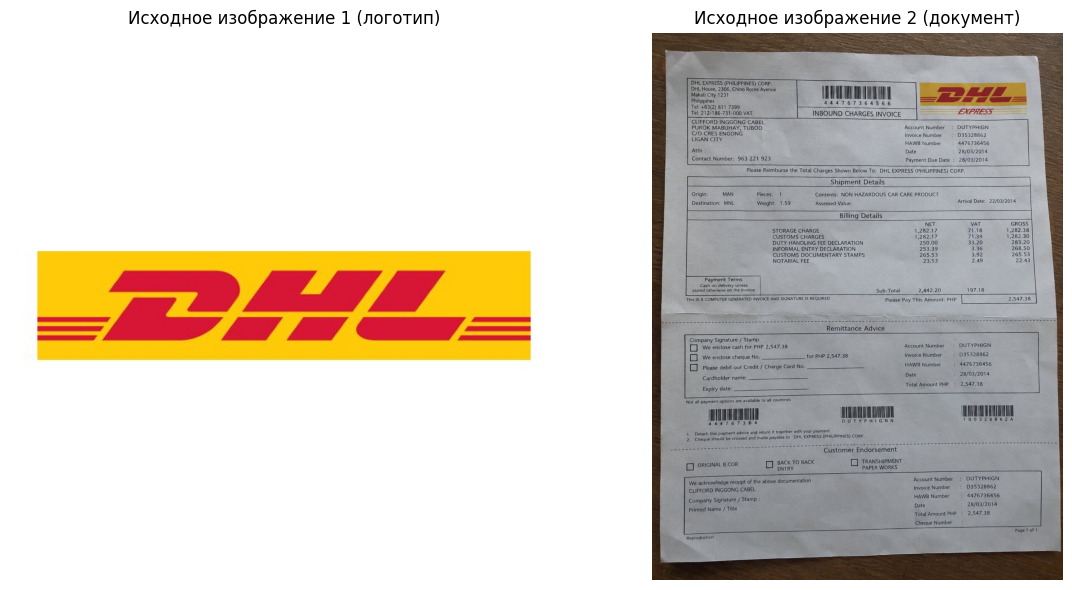

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img1 = cv2.imread('image1.jpg')
img2 = cv2.imread('image2.jpg')

img1_gray = cv2.imread('image1.jpg', cv2.IMREAD_GRAYSCALE)
img2_gray = cv2.imread('image2.jpg', cv2.IMREAD_GRAYSCALE)

if img1 is None or img2 is None:
    raise FileNotFoundError("Файлы image1.jpg или image2.jpg не найдены.")

def show_image(images, titles, figsize=(15, 5)):

    if not isinstance(images, (list, tuple)):
        images = [images]
    if not isinstance(titles, (list, tuple)):
        titles = [titles]

    fig, axes = plt.subplots(1, len(images), figsize=figsize)

    if len(images) == 1:
        axes = [axes]

    for ax, image, title in zip(axes, images, titles):
        if image.ndim == 2:
            ax.imshow(image, cmap='gray')
        else:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

        ax.set_title(title)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

show_image([img1, img2], ['Исходное изображение 1 (логотип)', 'Исходное изображение 2 (документ)'], figsize=(12, 6))


### Задание 1. Загрузите два изображения (логотип компании в чистом виде и на фото документа).


Изображение 1 (логотип): 600x600 px, каналов: 3
Изображение 2 (фото документа): 1086x1448 px, каналов: 3


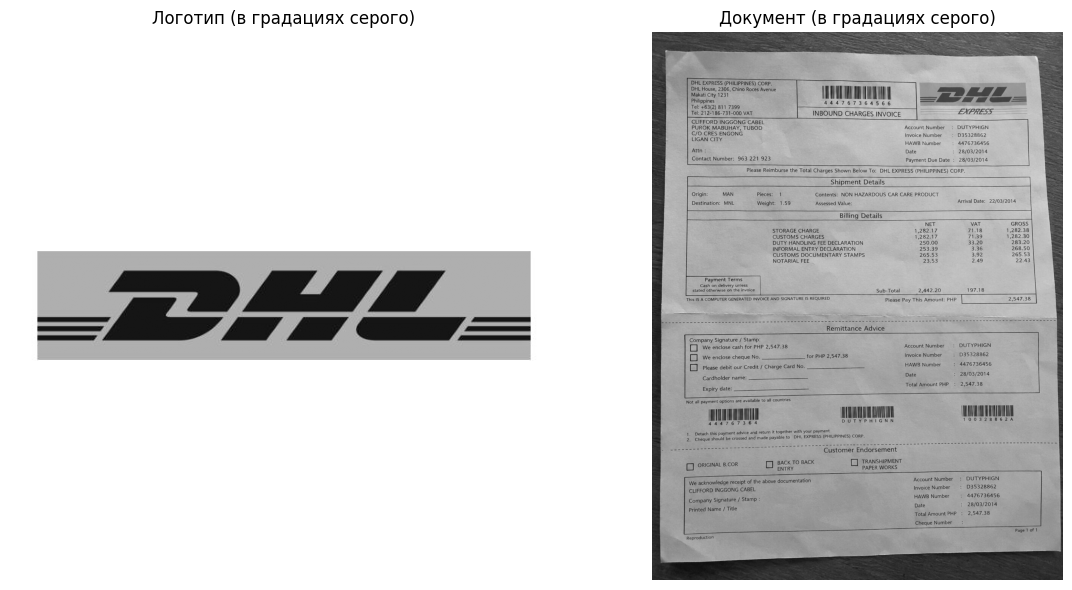

In [2]:
print(f"Изображение 1 (логотип): {img1.shape[1]}x{img1.shape[0]} px, каналов: {img1.shape[2]}")
print(f"Изображение 2 (фото документа): {img2.shape[1]}x{img2.shape[0]} px, каналов: {img2.shape[2]}")

show_image([img1_gray, img2_gray], ['Логотип (в градациях серого)', 'Документ (в градациях серого)'], figsize=(12, 6))


### Задание 2. Используйте SIFT для нахождения ключевых точек.


Количество ключевых точек в логотипе: 126
Количество ключевых точек в документе: 4093


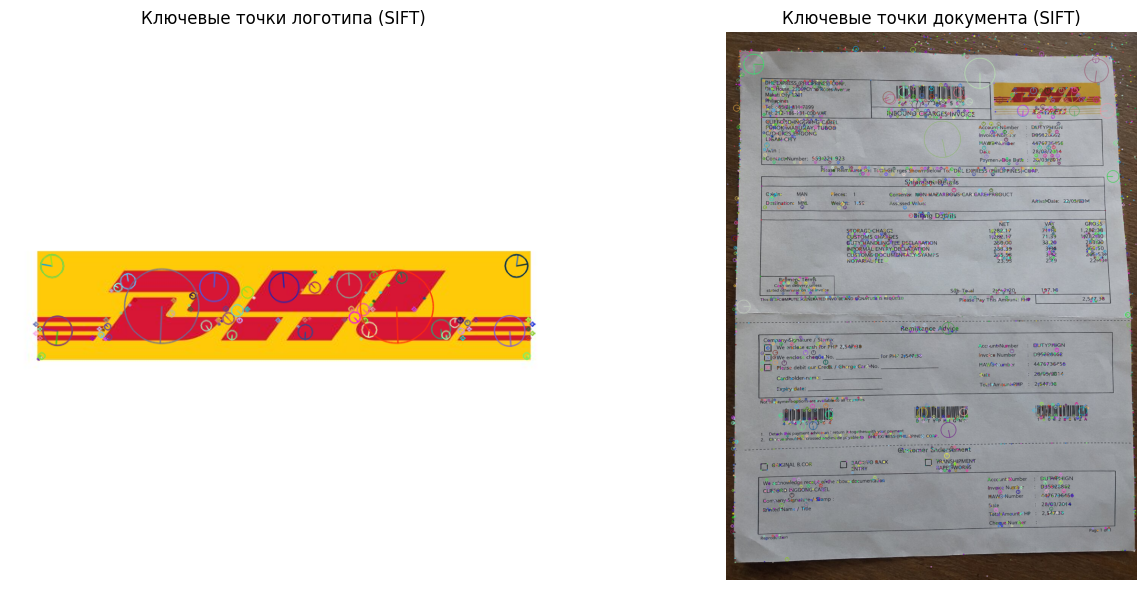

In [3]:
sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(img1_gray, None)
kp2, des2 = sift.detectAndCompute(img2_gray, None)

print(f"Количество ключевых точек в логотипе: {len(kp1)}")
print(f"Количество ключевых точек в документе: {len(kp2)}")

img1_kp = cv2.drawKeypoints(img1, kp1, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
img2_kp = cv2.drawKeypoints(img2, kp2, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

show_image([img1_kp, img2_kp], ['Ключевые точки логотипа (SIFT)', 'Ключевые точки документа (SIFT)'], figsize=(14, 6))


### Задание 3. Примените BFMatcher для сопоставления и выделите лучшие совпадения.


Общее количество сопоставлений BFMatcher: 126
Минимальное расстояние между дескрипторами: 39.27
Максимальное расстояние (среди лучших 30): 97.29


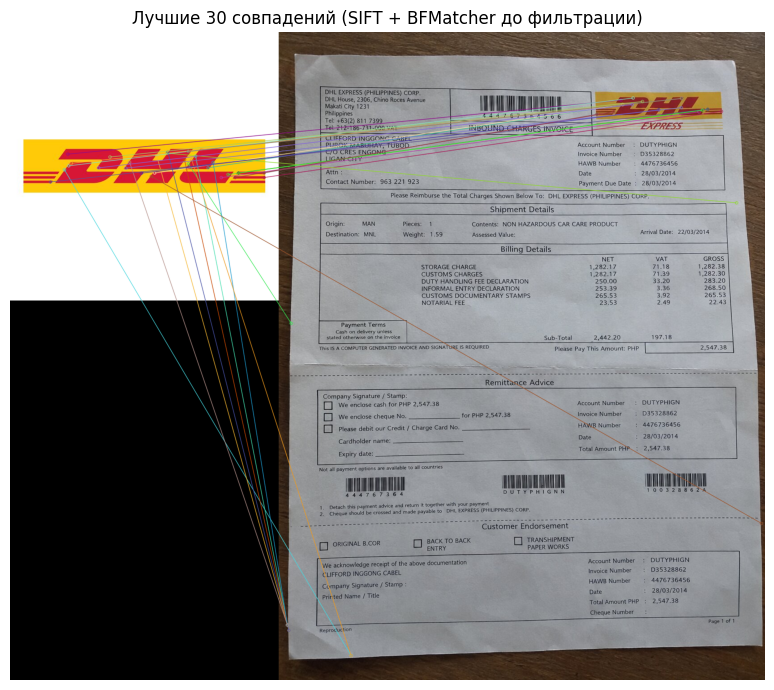

In [7]:
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

matches = bf.match(des1, des2)
matches = sorted(matches, key=lambda x: x.distance)

print(f"Общее количество сопоставлений BFMatcher: {len(matches)}")
print(f"Минимальное расстояние между дескрипторами: {matches[0].distance:.2f}")
print(f"Максимальное расстояние (среди лучших 30): {matches[29].distance:.2f}")

img_matches_bf = cv2.drawMatches(
    img1, kp1, img2, kp2, matches[:30], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

show_image(img_matches_bf, 'Лучшие 30 совпадений (SIFT + BFMatcher до фильтрации)', figsize=(16, 7))


### Задание 4. Примените фильтрацию по Лоу и сравните количество совпадений до и после.


Количество совпадений до фильтрации: 126
Количество совпадений после фильтрации по Лоу (порог 0.75): 38
Процент отфильтрованных шумов/неоднозначностей: 69.8%


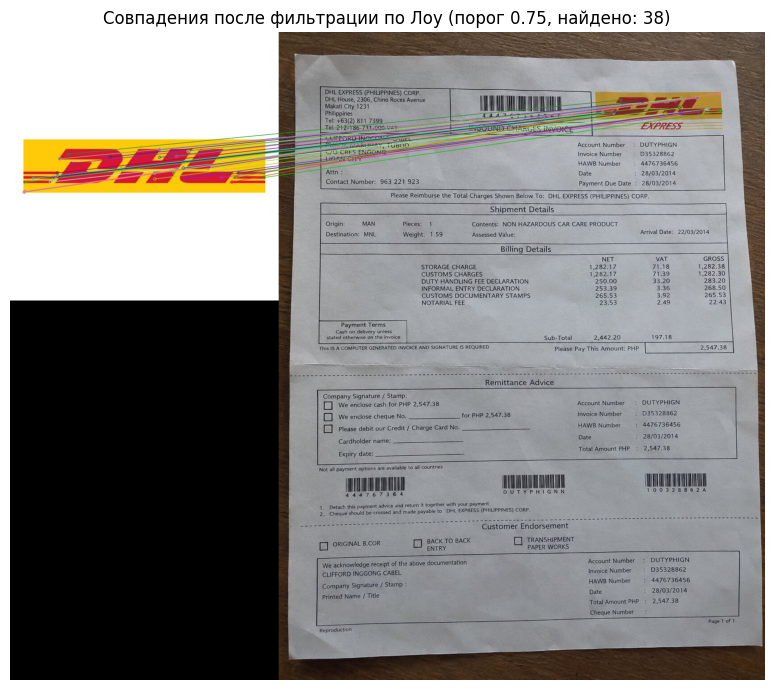

In [5]:
matches_knn = bf.knnMatch(des1, des2, k=2)

ratio_threshold = 0.75
good_matches = []

for m, n in matches_knn:
    if m.distance < ratio_threshold * n.distance:
        good_matches.append(m)

good_matches = sorted(good_matches, key=lambda x: x.distance)

pct_filtered = (1 - len(good_matches) / len(matches_knn)) * 100
print(f"Количество совпадений до фильтрации: {len(matches_knn)}")
print(f"Количество совпадений после фильтрации по Лоу (порог {ratio_threshold}): {len(good_matches)}")
print(f"Процент отфильтрованных шумов/неоднозначностей: {pct_filtered:.1f}%")

img_good_matches = cv2.drawMatches(
    img1, kp1, img2, kp2, good_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

show_image(img_good_matches, f'Совпадения после фильтрации по Лоу (порог {ratio_threshold}, найдено: {len(good_matches)})', figsize=(16, 7))


### Задание 5. Сделайте вывод: можно ли автоматически находить логотипы на документах.


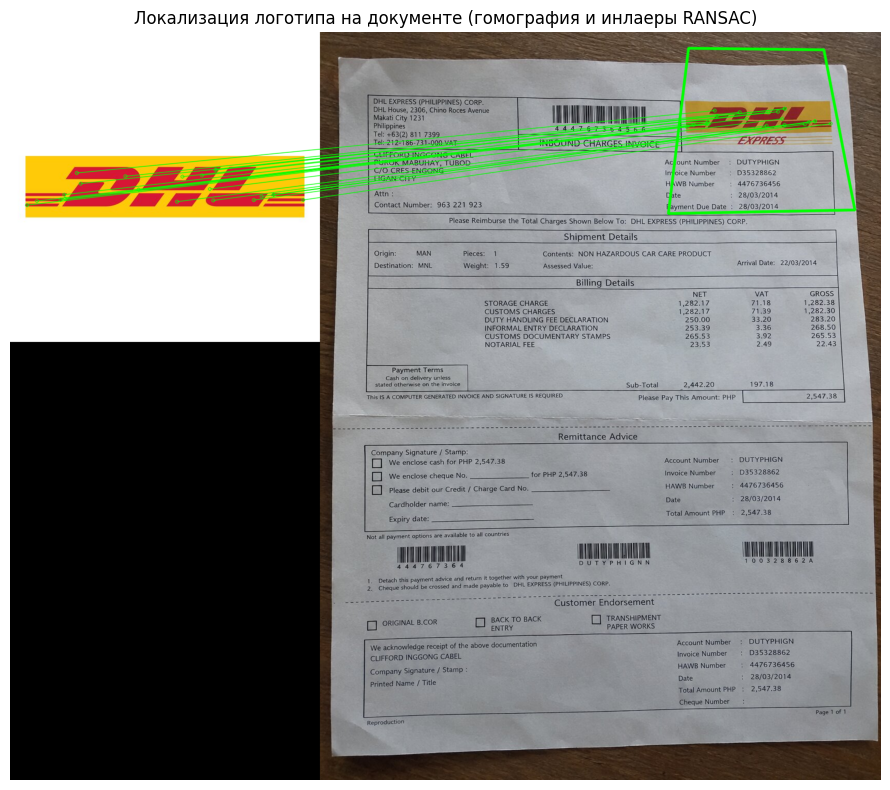

In [6]:
src_pts = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
dst_pts = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

M, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
matches_mask = mask.ravel().tolist()
inliers_count = sum(matches_mask)

h, w = img1.shape[:2]
pts = np.float32([[0, 0], [0, h - 1], [w - 1, h - 1], [w - 1, 0]]).reshape(-1, 1, 2)
dst = cv2.perspectiveTransform(pts, M)

img2_detected = img2.copy()
img2_detected = cv2.polylines(img2_detected, [np.int32(dst)], True, (0, 255, 0), 4, cv2.LINE_AA)

draw_params = dict(
    matchColor=(0, 255, 0),
    singlePointColor=None,
    matchesMask=matches_mask,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

img_localization = cv2.drawMatches(img1, kp1, img2_detected, kp2, good_matches, None, **draw_params)

show_image(img_localization, 'Локализация логотипа на документе (гомография и инлаеры RANSAC)', figsize=(16, 8))
